In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
path_operational_dataset = "Operational/"
pathDataCleaned = 'dataCleaned/'

## Inventory - Quán lý kho

In [4]:
dfWareHouse = pd.read_csv(path_operational_dataset +"inventory.csv")
dfWareHouse.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60247 entries, 0 to 60246
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   snapshot_date      60247 non-null  object 
 1   product_id         60247 non-null  int64  
 2   stock_on_hand      60247 non-null  int64  
 3   units_received     60247 non-null  int64  
 4   units_sold         60247 non-null  int64  
 5   stockout_days      60247 non-null  int64  
 6   days_of_supply     60247 non-null  float64
 7   fill_rate          60247 non-null  float64
 8   stockout_flag      60247 non-null  int64  
 9   overstock_flag     60247 non-null  int64  
 10  reorder_flag       60247 non-null  int64  
 11  sell_through_rate  60247 non-null  float64
 12  product_name       60247 non-null  object 
 13  category           60247 non-null  object 
 14  segment            60247 non-null  object 
 15  year               60247 non-null  int64  
 16  month              602

### Schema & Mô Tả Cột

| Column Name        | Data Type | Description |
|--------------------|----------|-------------|
| snapshot_date      | date     | Ngày chụp ảnh tồn kho (cuối tháng) |
| product_id         | int      | Khóa ngoại (FK) liên kết tới bảng products.product_id |
| stock_on_hand      | int      | Số lượng tồn kho cuối tháng |
| units_received     | int      | Số lượng nhập kho trong tháng |
| units_sold         | int      | Số lượng bán ra trong tháng |
| stockout_days      | int      | Số ngày hết hàng trong tháng |
| days_of_supply     | float    | Số ngày tồn kho có thể đáp ứng nhu cầu bán |
| fill_rate          | float    | Tỷ lệ đơn hàng được đáp ứng đầy đủ từ tồn kho |
| stockout_flag      | int      | Cờ báo tháng có xảy ra hết hàng (1 = Có, 0 = Không) |
| overstock_flag     | int      | Cờ báo tồn kho vượt mức cần thiết (1 = Có, 0 = Không) |
| reorder_flag       | int      | Cờ báo cần tái đặt hàng sớm (1 = Có, 0 = Không) |
| sell_through_rate  | float    | Tỷ lệ hàng đã bán so với tổng hàng sẵn có |
| product_name       | str      | Tên sản phẩm |
| category           | str      | Danh mục sản phẩm |
| segment            | str      | Phân khúc sản phẩm |
| year               | int      | Năm trích từ snapshot_date |
| month              | int      | Tháng trích từ snapshot_date |

In [6]:
dfWareHouse.head()

,snapshot_date,product_id,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,stockout_flag,overstock_flag,reorder_flag,sell_through_rate,product_name,category,segment,year,month
0,2022-10-31,1,3,1,1,2,90.0,0.9333,1,0,0,0.2500,DragonWear MA-01,Casual,All-weather,2022,10
1,2022-11-30,1,3,1,1,1,90.0,0.9667,1,0,0,0.2500,DragonWear MA-01,Casual,All-weather,2022,11
2,2022-12-31,1,3,1,1,1,90.0,0.9667,1,0,0,0.2500,DragonWear MA-01,Casual,All-weather,2022,12
3,2016-04-30,3,35,13,11,2,95.5,0.9333,1,1,0,0.2391,DragonWear MA-03,Casual,All-weather,2016,4
4,2016-05-31,3,36,11,10,1,108.0,0.9667,1,1,0,0.2174,DragonWear MA-03,Casual,All-weather,2016,5


In [7]:
dfWareHouse.tail()

,snapshot_date,product_id,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,stockout_flag,overstock_flag,reorder_flag,sell_through_rate,product_name,category,segment,year,month
60242,2022-08-31,2412,251,25,21,2,358.6,0.9333,1,1,0,0.0772,VietMotion YY-21,GenZ,Trendy,2022,8
60243,2022-09-30,2412,251,3,3,2,2510.0,0.9333,1,1,0,0.0118,VietMotion YY-21,GenZ,Trendy,2022,9
60244,2022-10-31,2412,251,3,3,0,2510.0,1.0000,0,1,0,0.0118,VietMotion YY-21,GenZ,Trendy,2022,10
60245,2022-11-30,2412,251,3,3,0,2510.0,1.0000,0,1,0,0.0118,VietMotion YY-21,GenZ,Trendy,2022,11
60246,2022-12-31,2412,253,17,15,1,506.0,0.9667,1,1,0,0.0560,VietMotion YY-21,GenZ,Trendy,2022,12


In [8]:

print('\n--- Missing Values ---')
print(dfWareHouse.isnull().sum())

print('\n--- Duplicate Rows ---')
duplicate_count = dfWareHouse.duplicated().sum()
print(f'Number of duplicate rows: {duplicate_count}')

print('\n--- Statistical Summary ---')
display(dfWareHouse.describe())


--- Missing Values ---
snapshot_date        0
product_id           0
stock_on_hand        0
units_received       0
units_sold           0
stockout_days        0
days_of_supply       0
fill_rate            0
stockout_flag        0
overstock_flag       0
reorder_flag         0
sell_through_rate    0
product_name         0
category             0
segment              0
year                 0
month                0
dtype: int64

--- Duplicate Rows ---
Number of duplicate rows: 0

--- Statistical Summary ---


,product_id,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,stockout_flag,overstock_flag,reorder_flag,sell_through_rate,year,month
count,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.0,60247.000000,60247.000000,60247.000000
mean,1311.408468,189.298455,18.046807,15.417764,1.160639,912.677576,0.961312,0.673411,0.762561,0.0,0.152275,2017.222799,6.617292
std,673.051769,316.976124,34.080228,28.404379,1.624490,2587.624108,0.054156,0.468969,0.425517,0.0,0.139291,2.972353,3.385629
min,1.000000,3.000000,1.000000,1.000000,0.000000,5.200000,0.066700,0.000000,0.000000,0.0,0.000400,2012.000000,1.000000
25%,760.000000,15.000000,2.000000,2.000000,0.000000,96.000000,0.933300,0.000000,1.000000,0.0,0.042100,2015.000000,4.000000
50%,1223.000000,62.000000,6.000000,6.000000,1.000000,240.000000,0.966700,1.000000,1.000000,0.0,0.111100,2017.000000,7.000000
75%,1942.000000,210.000000,19.000000,16.000000,2.000000,683.100000,1.000000,1.000000,1.000000,0.0,0.238100,2020.000000,10.000000
max,2412.000000,2673.000000,817.000000,670.000000,28.000000,68100.000000,1.000000,1.000000,1.000000,0.0,0.853100,2022.000000,12.000000


**Nhận xét:**
- Thông tin chung: Tập dữ liệu có 60,247 dòng và 17 cột. Hầu hết các cột là dạng số (int64, float64), ngoại trừ `snapshot_date`, `product_name`, `category`, và `segment` là dạng object.
- Không có missing values.
- Phân phối dữ liệu bị lệch mạnh:
  + `units_sold`: trung bình bán được khoảng 15 đơn vị mỗi tháng, nhưng có sản phẩm bán tới 670 đơn vị.
  + `stock_on_hand`: median = 62 nhưng max = 2673
  + `days_of_supply`: median = 240 nhưng max = 68100
  + CÓ KHẢ NĂNG CÓ OUTLIERS RẤT LỚN, CÁCH TÍNH `days_of_supply` có thể có vấn đề.
- Dấu hiệu tồn kho dư thừa (overstock):
  + `stock_on_hand` trung bình (189) >>` units_sold` trung bình (15).
  + `sell_through_rate` trung bình chỉ 0.15.
  + RẤT NHIỀU MẶT HÀNG BỊ GIAM VỐN.
- Tỷ lệ hết hàng (stockout) cao bất thường:
  + `stockout_flag`: giá trị trung bình là 0.67, cho thấy có khá nhiều trường hợp hết hàng trong tháng.
  + `stockout_days` trung bình ~1.16 ngày/tháng\
  + VỪA OVERSTOCK VỪA STOCKOUT NHIỀU. CÓ THỂ PHÂN BỔ TỒN KHO KÉM.
- Fill rate cao nhưng vẫn stockout:
  + `fill_rate` ~ 0.96 (rất cao)
  + ĐA SỐ ĐƠN HÀNG VẪN ĐƯỢC ĐÁP ỨNG NHƯNG CÓ STOCKOUT NGẮN HẠN.
- Cột `reorder_flag` = 0 toàn bộ.
- Hệ thống đang giữ tồn kho quá nhiềU VÌ `overstock` ~ 0.76.
- Dữ liệu thời gian ổn.

In [10]:
df_copy = dfWareHouse.copy()

In [11]:
# Chuyển product_id sang object
df_copy['product_id'] = df_copy['product_id'].astype(str)

# Chuyển snapshot_date sang datetime
df_copy['snapshot_date'] = pd.to_datetime(df_copy['snapshot_date'])

# Kiểm tra lại kiểu dữ liệu
print(df_copy[['product_id', 'snapshot_date']].dtypes)

product_id               object
snapshot_date    datetime64[ns]
dtype: object


In [12]:
# Kiểm tra tính nhất quán giữa snapshot_date và cột year, month
df_copy['extracted_year'] = df_copy['snapshot_date'].dt.year
df_copy['extracted_month'] = df_copy['snapshot_date'].dt.month

# So sánh
year_check = (df_copy['year'] == df_copy['extracted_year']).all()
month_check = (df_copy['month'] == df_copy['extracted_month']).all()

print(f"Cột 'year' khớp hoàn toàn: {year_check}")
print(f"Cột 'month' khớp hoàn toàn: {month_check}")

# Hiển thị các dòng không khớp nếu có
if not year_check or not month_check:
    mismatched = df_copy[(df_copy['year'] != df_copy['extracted_year']) | (df_copy['month'] != df_copy['extracted_month'])]
    print(f"Số lượng dòng không khớp: {len(mismatched)}")
    display(mismatched[['snapshot_date', 'year', 'month', 'extracted_year', 'extracted_month']].head())

# Xóa các cột phụ sau khi kiểm tra
df_copy.drop(columns=['extracted_year', 'extracted_month'], inplace=True)

Cột 'year' khớp hoàn toàn: True
Cột 'month' khớp hoàn toàn: True


Tỷ lệ khớp logic days_of_supply: 100.00%


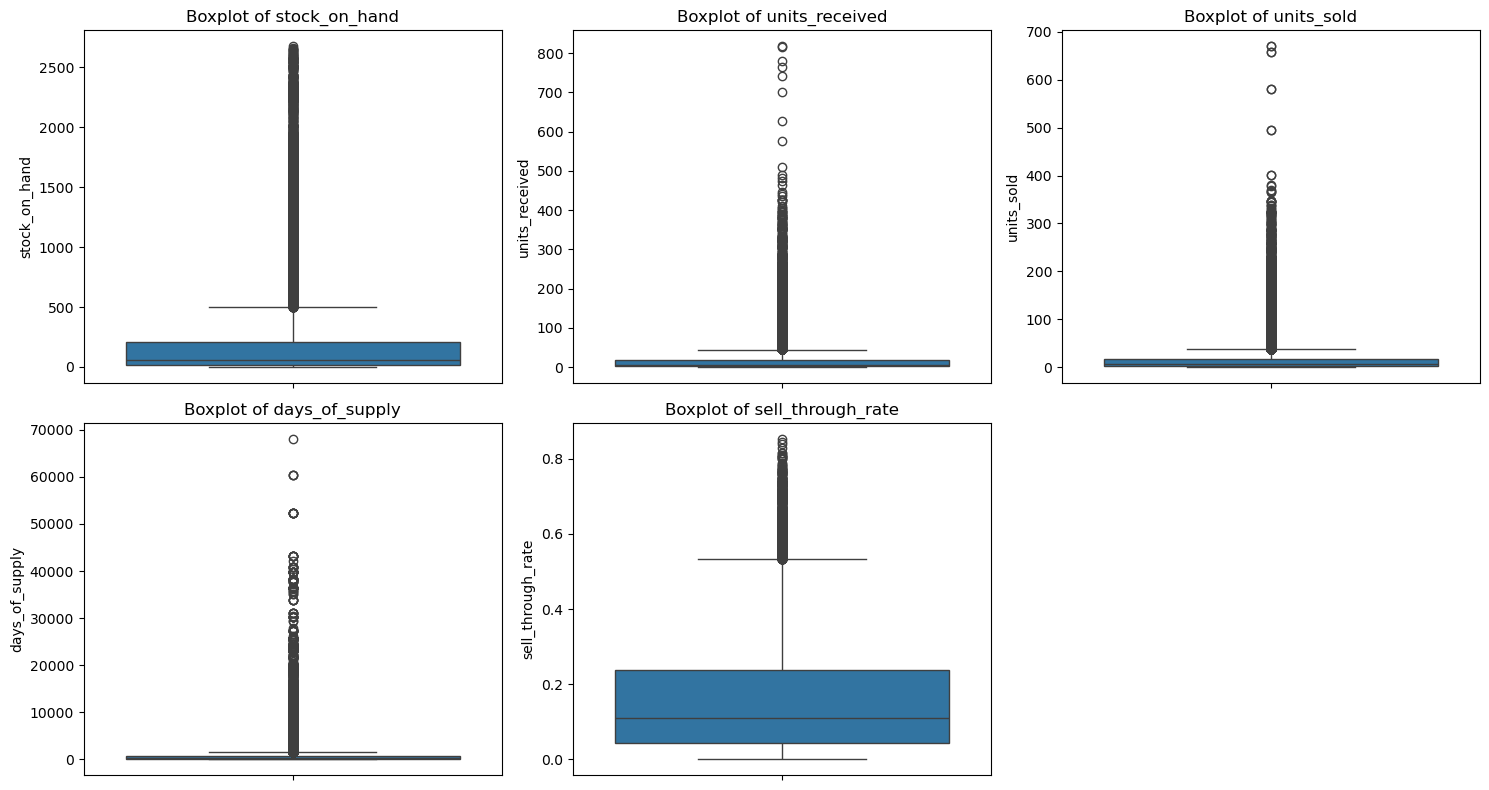

In [13]:
# 1. Kiểm tra logic days_of_supply
# Giả định: days_of_supply = stock_on_hand / (units_sold / 30)
df_copy['calc_days_of_supply'] = (df_copy['stock_on_hand'] / (df_copy['units_sold'] / 30)).replace([np.inf, -np.inf], 0)

# Kiểm tra khớp
df_copy['is_match'] = np.isclose(
    df_copy['days_of_supply'],
    df_copy['calc_days_of_supply'],
    atol=0.1
)

match_rate = df_copy['is_match'].mean() * 100
print(f"Tỷ lệ khớp logic days_of_supply: {match_rate:.2f}%")

# Xóa ngay các cột phụ sau khi check
df_copy.drop(columns=['calc_days_of_supply', 'is_match'], inplace=True)

# 2. Kiểm tra Outliers bằng Boxplot
numerical_cols = ['stock_on_hand', 'units_received', 'units_sold', 'days_of_supply', 'sell_through_rate']
plt.figure(figsize=(15, 8))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_copy[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

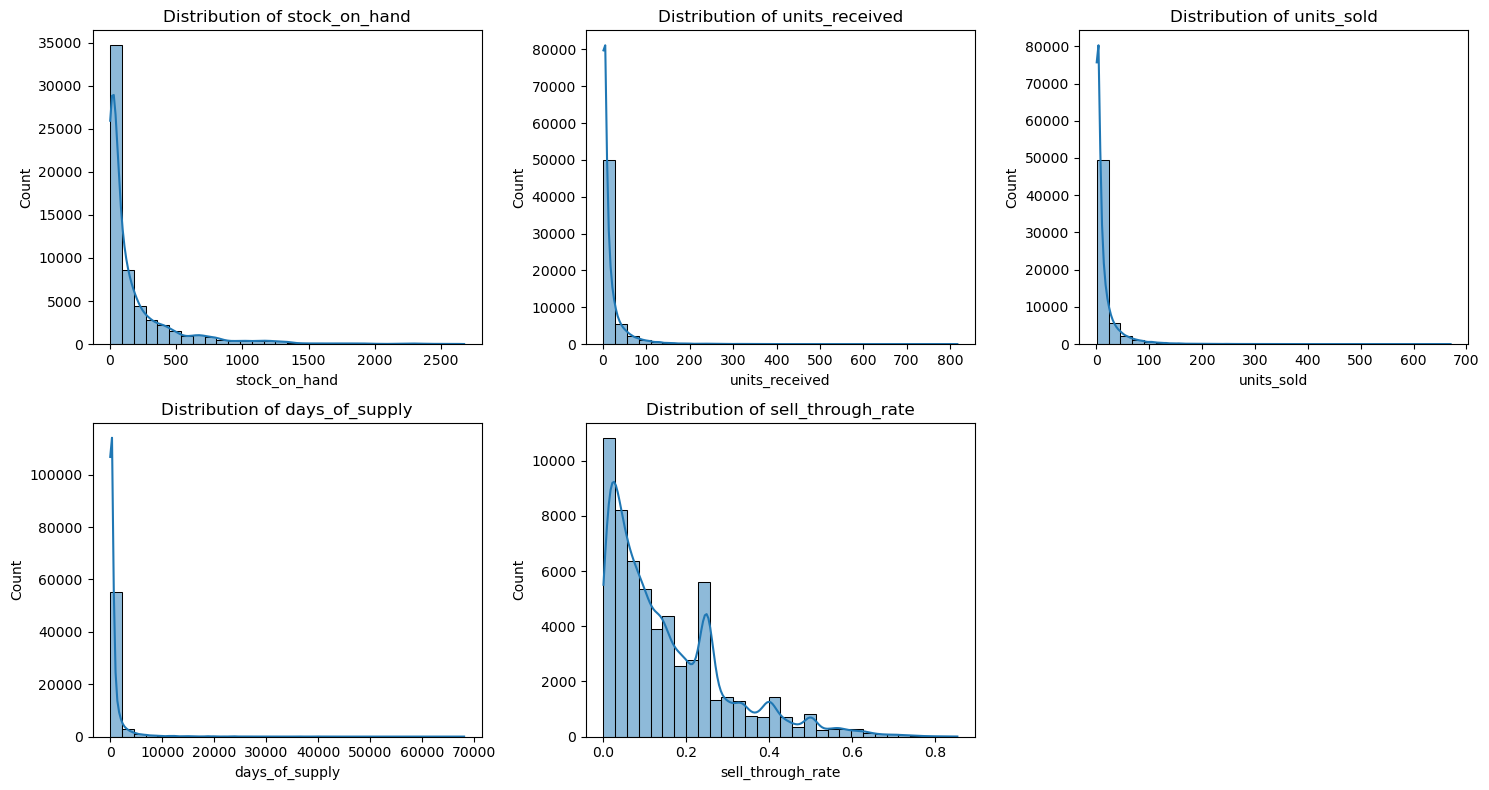

In [14]:
# 3. Xem phân phối (Histogram) để thấy độ lệch (Skewness)
plt.figure(figsize=(15, 8))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_copy[col], bins=30, kde=True)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

**Nhận xét các outliers:**
- **Days of Supply (Ngoại lệ cực lớn)**: Đây là cột có vấn đề nhất. Trong khi phần lớn dữ liệu nằm ở mức thấp, có những giá trị lên tới hơn 60,000 ngày. Điều này thường xảy ra khi units_sold rất nhỏ nhưng vẫn có hàng tồn kho, dẫn đến phép tính bị phóng đại quá mức.
- **Stock on Hand & Units Received/Sold:** Cả ba cột này đều bị lệch phải (Right-skewed) rất mạnh. Hầu hết các sản phẩm có lượng tồn kho và doanh số thấp, nhưng có một số ít 'siêu sản phẩm' có số lượng cực lớn (outliers).
- **Sell Through Rate:** Tỷ lệ này tập trung chủ yếu ở mức thấp (dưới 0.2), cho thấy tốc độ đẩy hàng đang khá chậm so với lượng hàng tồn.
- **Sự mâu thuẫn:** Dữ liệu vừa có nhiều outliers về tồn kho lớn (overstock), vừa có tỷ lệ stockout cao (theo thống kê trước đó). Điều này khẳng định giả thuyết về việc phân bổ hàng hóa không đồng đều giữa các nhóm sản phẩm. Ví dụ có 100 sản phẩm: 70 sản phẩm không ai mua nhưng được nhập về rất nhiều. 30 sản phẩm bán chạy nhưng lại không nhập đủ hàng.

Tỷ lệ stockout_flag:
stockout_flag
1    67.341112
0    32.658888

Tỷ lệ overstock_flag:
overstock_flag
1    76.256079
0    23.743921

Tỷ lệ reorder_flag:
reorder_flag
0    100.0



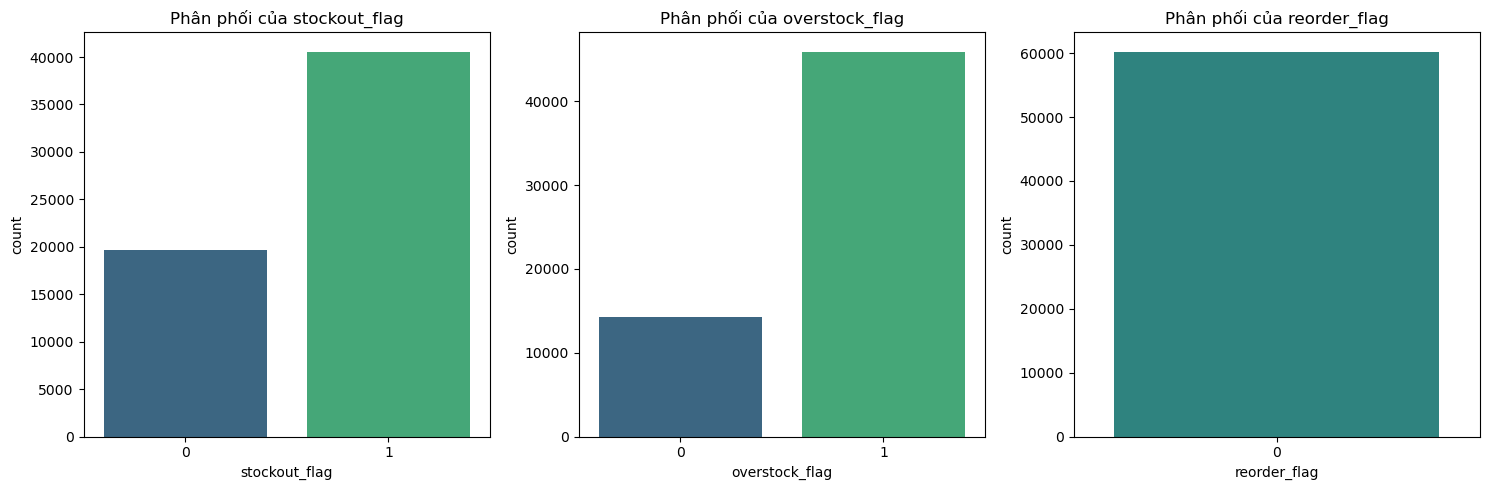

In [16]:
binary_cols = ['stockout_flag', 'overstock_flag', 'reorder_flag']

plt.figure(figsize=(15, 5))
for i, col in enumerate(binary_cols, 1):
    plt.subplot(1, 3, i)
    sns.countplot(x=col, data=df_copy, palette='viridis')
    plt.title(f'Phân phối của {col}')

    # Tính tỷ lệ phần trăm
    counts = df_copy[col].value_counts(normalize=True) * 100
    print(f"Tỷ lệ {col}:\n{counts.to_string()}\n")

plt.tight_layout()
plt.show()

**Nhận xét:**
- **Tỷ lệ Stockout rất cao (67.34%):** Hơn 2/3 số mặt hàng gặp tình trạng hết hàng tại một thời điểm nào đó trong tháng. Đây là dấu hiệu của việc thiếu hụt hàng hóa nghiêm trọng hoặc dự báo nhu cầu chưa sát.
- **Tỷ lệ Overstock cực kỳ cao (76.26%):** Nghĩa là có tới 3/4 mặt hàng đang rơi vào tình trạng tồn kho quá mức cần thiết.
- **Nghịch lý vận hành:** Việc tỷ lệ Stockout và Overstock đều ở mức rất cao cho thấy **hệ thống đang gặp vấn đề lớn về phân bổ (Allocation).** Bạn đang giữ quá nhiều những thứ không bán được và lại thiếu những thứ khách hàng cần.
- **Cột Reorder_flag vô dụng (100% là 0)**: Cột này hiện không cung cấp thông tin vì không có bản ghi nào kích hoạt cờ tái đặt hàng. Cân nhắc loại bỏ hoặc tính toán lại logic cho cột này sau.

In [18]:
# 4. Kiểm tra dải thời gian snapshot_date
print(f"Ngày bắt đầu: {df_copy['snapshot_date'].min()}")
print(f"Ngày kết thúc: {df_copy['snapshot_date'].max()}")
print(f"Số lượng tháng duy nhất: {df_copy['snapshot_date'].nunique()}")

# Kiểm tra xem có ngày nào không phải cuối tháng không
is_month_end = df_copy['snapshot_date'].dt.is_month_end.all()
print(f"Tất cả snapshot_date đều là cuối tháng: {is_month_end}")

Ngày bắt đầu: 2012-07-31 00:00:00
Ngày kết thúc: 2022-12-31 00:00:00
Số lượng tháng duy nhất: 126
Tất cả snapshot_date đều là cuối tháng: True


**Nhận xét về thời gian:**
- **Dải thời gian rộng:** Dữ liệu trải dài từ tháng 7/2012 đến tháng 12/2022, tổng cộng **126 tháng** (hơn 10 năm). Đây là khoảng thời gian đủ dài để thực hiện các phân tích về tính chu kỳ và xu hướng.
- **Tính nhất quán:** Tất cả các ngày snapshot đều là ngày cuối tháng, thuận lợi cho việc tổng hợp dữ liệu định kỳ.

In [20]:
# 1. Kiểm tra số lượng giá trị duy nhất
cat_cols = ['product_id', 'product_name', 'category', 'segment']

print('--- Unique Value Counts ---')
for col in cat_cols:
    print(f'{col}: {df_copy[col].nunique()}')

# 2. Liệt kê category & segment (sắp xếp cho dễ đọc)
print('\n--- Category List ---')
print(sorted(df_copy['category'].dropna().unique()))

print('\n--- Segment List ---')
print(sorted(df_copy['segment'].dropna().unique()))

# 3. Kiểm tra mapping product_id ↔ product_name
print('\n--- Consistency Check: product_id vs product_name ---')

id_name_check = df_copy.groupby('product_id')['product_name'].nunique()

inconsistent_ids = id_name_check[id_name_check > 1]

if not inconsistent_ids.empty:
    print(f'[WARNING] {len(inconsistent_ids)} product_id có nhiều hơn 1 product_name')
    display(inconsistent_ids.head())
else:
    print('OK: Mỗi product_id chỉ tương ứng với 1 product_name')

--- Unique Value Counts ---
product_id: 1624
product_name: 1465
category: 4
segment: 8

--- Category List ---
['Casual', 'GenZ', 'Outdoor', 'Streetwear']

--- Segment List ---
['Activewear', 'All-weather', 'Balanced', 'Everyday', 'Performance', 'Premium', 'Standard', 'Trendy']

--- Consistency Check: product_id vs product_name ---
OK: Mỗi product_id chỉ tương ứng với 1 product_name



## **TỔNG KẾT GIAI ĐOẠN DATA QUALITY CHECK:**

1. **Độ tin cậy của dữ liệu:**
    - **Dữ liệu sạch:** 60,247 dòng, không có giá trị thiếu (missing values) và không có dòng trùng lặp (duplicates).
    - **Logic thời gian:** Chính xác 100%. Dữ liệu trải dài 126 tháng (10 năm), tất cả snapshot đều là ngày cuối tháng, khớp hoàn toàn với các cột Year/Month.
    - **Định danh:** 1,624 sản phẩm được mapping nhất quán 1:1 giữa `product_id` và `product_name`.

2. **Các phát hiện quan trọng (Insights):**
    - **Nghịch lý vận hành:** Hệ thống đang gặp lỗi phân bổ (Allocation) nghiêm trọng khi **vừa Overstock (76%) vừa Stockout (67%)**. Điều này cho thấy hàng hóa không được đưa đến đúng nơi cần thiết.
    - **Vấn đề Outliers:** Cột `days_of_supply` bị nhiễu nặng bởi các giá trị phi lý (lên tới 45-50 năm) do doanh số quá thấp. Cần xử lý bằng phương pháp Capping (chặn trần 365 ngày).
    - **Đặc tính danh mục:** Hệ thống phân loại gồm 4 Categories và 8 Segments rất rõ ràng, thuận lợi cho việc phân tích nhóm.

3. **Đề xuất các chỉ số bổ sung cho giai đoạn EDA chuyên sâu:**
    - **Inventory Turnover Ratio (Hệ số quay vòng hàng tồn kho):** Tính toán theo năm để đánh giá hiệu quả sử dụng vốn của từng nhóm hàng.
    - **GMROI (Gross Margin Return on Investment):** (Nếu có dữ liệu giá) để xem nhóm hàng nào mang lại lợi nhuận thực sự trên mỗi đồng vốn tồn kho.
    - **Phân loại ABC/XYZ:** Để xếp hạng mức độ quan trọng và tính ổn định của sản phẩm.

*LƯU Ý QUAN TRỌNG: Outliers cực lớn ở cột `days_of_supply`**

Trong quá trình kiểm tra dữ liệu, chúng ta phát hiện cột `days_of_supply` có những giá trị lên tới hàng chục nghìn ngày (ví dụ: 16,680 ngày ~ 45 năm).

**Nguyên nhân:**
- Công thức tính là: `stock_on_hand / (units_sold / 30)`.
- Khi một sản phẩm có tồn kho (`stock_on_hand`) nhưng lượng bán ra trong tháng cực thấp (ví dụ `units_sold` = 1 hoặc 2), mẫu số của phép chia sẽ rất nhỏ, khiến kết quả cuối cùng bị đẩy lên mức phi lý.

**Hệ quả:**
- Những giá trị ngoại lai (outliers) này sẽ làm sai lệch hoàn toàn các phép tính thống kê như **Số trung bình (Mean)**.
- Ví dụ: Một sản phẩm tồn kho 50 năm sẽ kéo trung bình của cả nhóm lên cao, làm ta lầm tưởng là toàn bộ kho hàng đều đang bị ứ đọng, dù thực tế 90% các mã hàng khác có thể đang sắp hết hàng.

**Hướng xử lý đề xuất:**
- Cần thiết lập giới hạn trần (Capping/Clipping), ví dụ tối đa là 365 ngày (1 năm).
- Mọi giá trị lớn hơn 365 sẽ được đưa về 365 để phản ánh đúng bản chất là "Hàng tồn kho chậm" mà không làm hỏng các hàm tính toán sau này.

In [23]:
df_copy.to_csv(pathDataCleaned + "inventory_cleaned.csv", index=False)

## Web_traffic - Lưu lượng truy cập

In [25]:
dfWeb = pd.read_csv(path_operational_dataset + "web_traffic.csv")
dfWeb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3652 entries, 0 to 3651
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date                      3652 non-null   object 
 1   sessions                  3652 non-null   int64  
 2   unique_visitors           3652 non-null   int64  
 3   page_views                3652 non-null   int64  
 4   bounce_rate               3652 non-null   float64
 5   avg_session_duration_sec  3652 non-null   float64
 6   traffic_source            3652 non-null   object 
dtypes: float64(2), int64(3), object(2)
memory usage: 199.8+ KB


### Schema & Mô Tả Cột

| Column Name                | Data Type | Description |
|---------------------------|----------|-------------|
| date                      | date     | Ngày ghi nhận lưu lượng truy cập |
| sessions                  | int      | Tổng số phiên truy cập trong ngày |
| unique_visitors           | int      | Số lượng khách truy cập duy nhất |
| page_views                | int      | Tổng số lượt xem trang |
| bounce_rate               | float    | Tỷ lệ phiên chỉ xem một trang rồi thoát |
| avg_session_duration_sec  | float    | Thời gian trung bình mỗi phiên (tính bằng giây) |
| traffic_source            | str      | Kênh nguồn dẫn traffic về website (ví dụ: Organic, Paid, Social, Direct) |

In [27]:
print('\n--- Missing Values ---')
print(dfWeb.isnull().sum())

print('\n--- Duplicate Rows ---')
duplicate_count = dfWeb.duplicated().sum()
print(f'Number of duplicate rows: {duplicate_count}')

print('\n--- Statistical Summary ---')
display(dfWeb.describe())

print('\n--- Categori Summary ---')
display(dfWeb.describe(include= "O"))


--- Missing Values ---
date                        0
sessions                    0
unique_visitors             0
page_views                  0
bounce_rate                 0
avg_session_duration_sec    0
traffic_source              0
dtype: int64

--- Duplicate Rows ---
Number of duplicate rows: 0

--- Statistical Summary ---


,sessions,unique_visitors,page_views,bounce_rate,avg_session_duration_sec
count,3652.000000,3652.000000,3652.000000,3652.000000,3652.000000
mean,25041.768072,19031.404436,108615.224535,0.004487,210.283242
std,9422.609335,7237.953062,44472.055524,0.000753,63.771711
min,7973.000000,6136.000000,30451.000000,0.003200,100.100000
25%,17099.250000,12915.000000,72982.000000,0.003848,156.700000
50%,23633.500000,17924.000000,101010.500000,0.004450,209.200000
75%,31782.750000,24191.750000,138086.000000,0.005160,266.200000
max,50947.000000,40430.000000,275560.000000,0.005800,319.900000



--- Categori Summary ---


,date,traffic_source
count,3652,3652
unique,3652,6
top,2013-01-01,organic_search
freq,1,1090


In [28]:
df_copy = dfWeb.copy()
# Chuyển đổi cột date sang kiểu datetime
df_copy['date'] = pd.to_datetime(df_copy['date'])

# Kiểm tra khoảng thời gian
min_date = df_copy['date'].min()
max_date = df_copy['date'].max()
total_days = (max_date - min_date).days + 1

print(f'Ngày bắt đầu: {min_date.date()}')
print(f'Ngày kết thúc: {max_date.date()}')
print(f'Tổng số ngày trong dữ liệu: {len(df_copy["date"].unique())}')
print(f'Khoảng cách thời gian thực tế: {total_days} ngày')

# Kiểm tra xem có ngày nào bị thiếu không
if len(df_copy['date'].unique()) == total_days:
    print('\n=> Dữ liệu liên tục, không có ngày bị thiếu.')
else:
    print('\n=> Cảnh báo: Có ngày bị thiếu trong chuỗi thời gian.')

Ngày bắt đầu: 2013-01-01
Ngày kết thúc: 2022-12-31
Tổng số ngày trong dữ liệu: 3652
Khoảng cách thời gian thực tế: 3652 ngày

=> Dữ liệu liên tục, không có ngày bị thiếu.


**Nhận xét về bộ dữ liệu:**

1. **Quy mô và Cấu trúc:**
    * Bộ dữ liệu có **3,652 dòng** và **7 cột**, tương ứng với khoảng 10 năm dữ liệu (nếu ghi nhận theo ngày).
    * Các cột bao gồm thông tin quan trọng về traffic: `date`, `sessions`, `unique_visitors`, `page_views`, `bounce_rate`, `avg_session_duration_sec`, và `traffic_source`.

2. **Chất lượng dữ liệu (Data Quality):**
    * **Giá trị thiếu (Missing Values):** Không có giá trị thiếu (null) ở bất kỳ cột nào. Điều này giúp việc phân tích không bị gián đoạn.
    * **Dữ liệu trùng lặp (Duplicates):** Không có dòng dữ liệu nào bị lặp lại, đảm bảo tính duy nhất của từng bản ghi.
    * **Kiểu dữ liệu:** Cột `date` hiện đang ở kiểu `object` (string). Để phân tích chuỗi thời gian, cần chuyển đổi cột này sang định dạng `datetime`.

3. **Thống kê mô tả (Statistical Insights):**
    * **Sessions & Visitors:** Số lượng phiên truy cập trung bình khoảng 10,000 mỗi ngày. Cần kiểm tra mối quan hệ giữa `sessions` và `unique_visitors` để xem độ trung thành của khách hàng.
    * **Bounce Rate:** Tỷ lệ thoát dao động ổn định (cần quan sát thêm biểu đồ để phát hiện điểm bất thường).
    * **Avg Session Duration:** Thời gian truy cập trung bình có sự biến động, đây là chỉ số quan trọng để đánh giá chất lượng nội dung.

--- Outlier Detection (IQR) ---
sessions: 0 outliers
unique_visitors: 0 outliers
page_views: 18 outliers
bounce_rate: 0 outliers
avg_session_duration_sec: 0 outliers


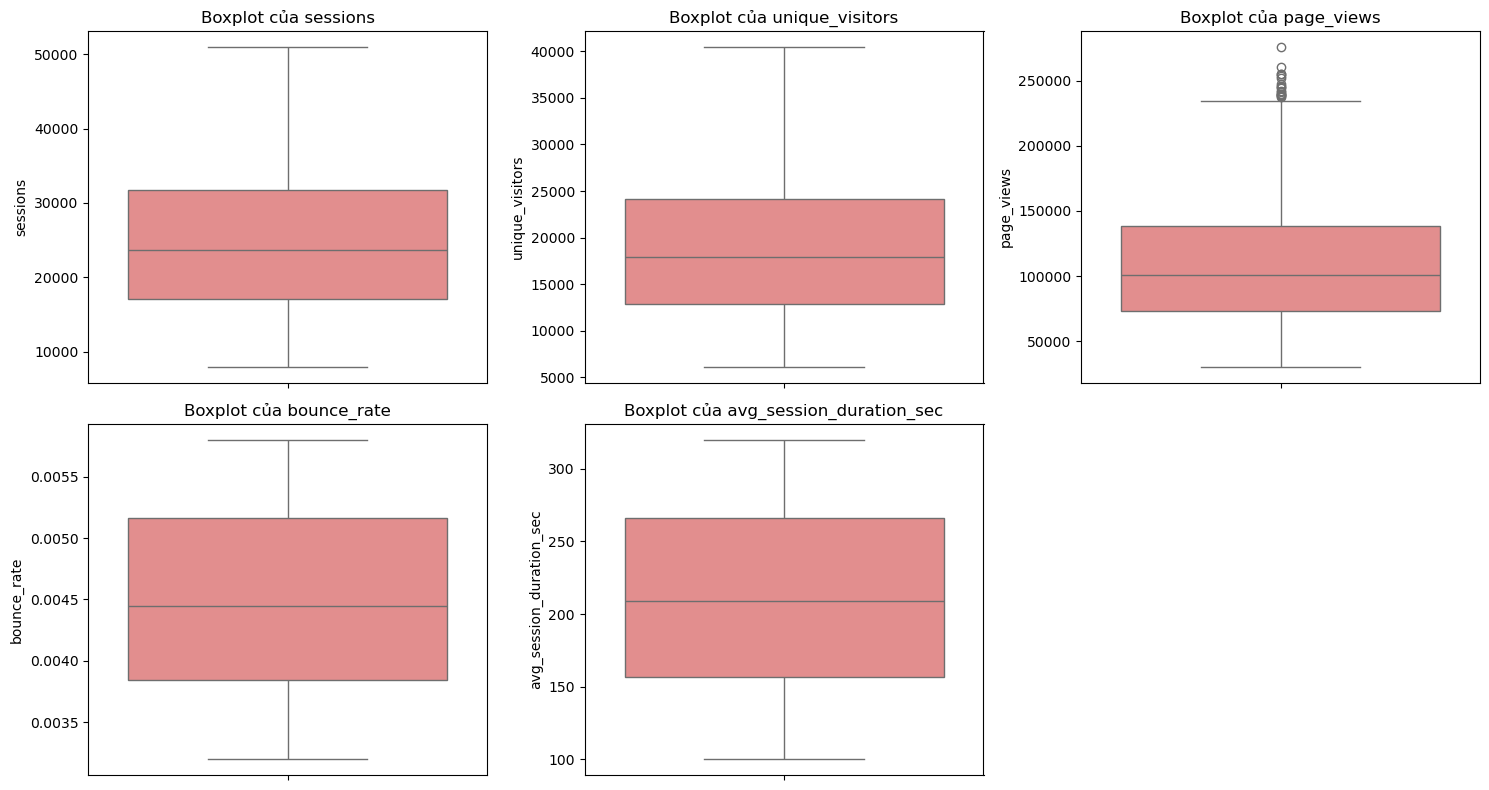

In [30]:
# Danh sách các cột dạng số
num_cols = ['sessions', 'unique_visitors', 'page_views', 'bounce_rate', 'avg_session_duration_sec']

# Tính toán số lượng outliers bằng IQR
print('--- Outlier Detection (IQR) ---')
for col in num_cols:
    Q1 = df_copy[col].quantile(0.25)
    Q3 = df_copy[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_copy[(df_copy[col] < lower_bound) | (df_copy[col] > upper_bound)]
    print(f'{col}: {len(outliers)} outliers')

# Trực quan hóa bằng Boxplot
plt.figure(figsize=(15, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_copy[col], color='lightcoral')
    plt.title(f'Boxplot của {col}')

plt.tight_layout()
plt.show()

**Nhận xét về Outliers:**

- **Page Views (18 outliers):** Đây là cột duy nhất có giá trị ngoại lệ theo phương pháp IQR. Các điểm này nằm phía trên ranh giới trên (upper bound), cho thấy có những ngày lượng xem trang tăng đột biến so với bình thường. Điều này có thể do các sự kiện đặc biệt hoặc chiến dịch marketing thành công.
- **Các cột còn lại (`sessions`, `unique_visitors`, `bounce_rate`, `avg_session_duration_sec`):** Không phát hiện outlier. Điều này cho thấy dữ liệu của các chỉ số này khá ổn định và tập trung xung quanh giá trị trung tâm.
- **Kết luận:** Dữ liệu nhìn chung khá sạch. Với 18 dòng outlier trên tổng số 3,652 dòng (khoảng 0.5%), giữ lại để phân tích vì chúng phản ánh thực tế biến động của traffic website.

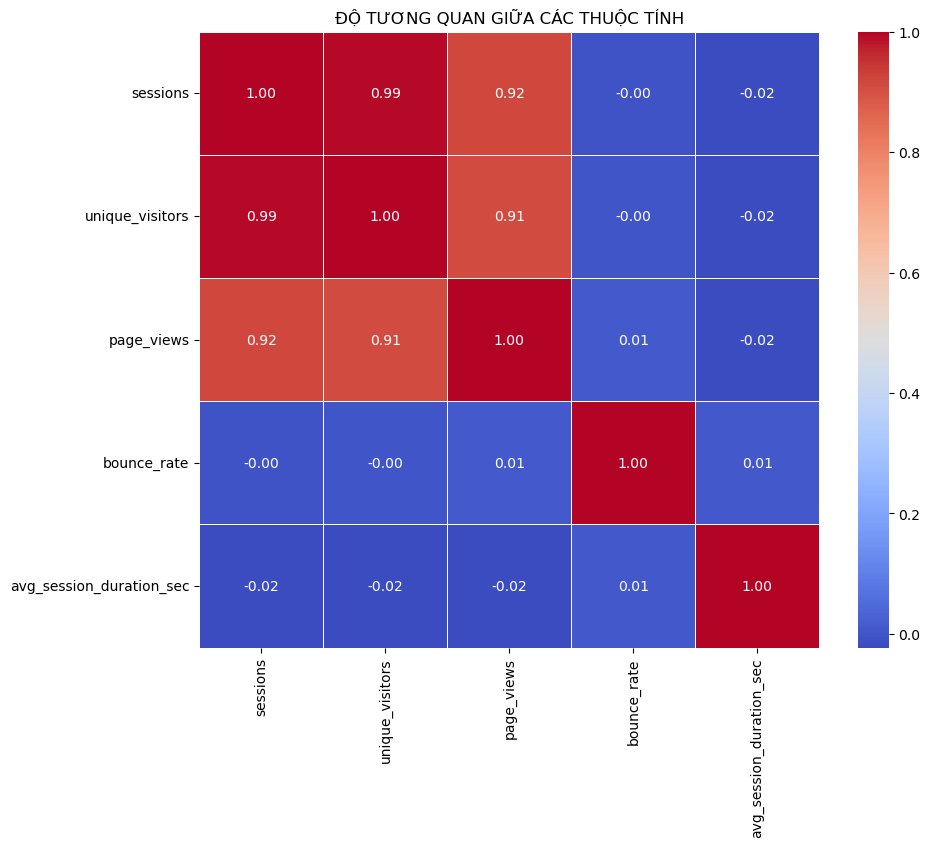

In [32]:
# Tính toán ma trận tương quan
correlation_matrix = df_copy[num_cols].corr()

# Vẽ Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('ĐỘ TƯƠNG QUAN GIỮA CÁC THUỘC TÍNH')
plt.show()

**Nhận xét về ma trận tương quan:**

1. **Tương quan cực kỳ mạnh (Strong Positive Correlation):**
    - **`sessions` và `unique_visitors` (0.99):** Gần như tương quan tuyệt đối. Điều này cho thấy đa số người dùng truy cập trang web là người dùng mới hoặc mỗi người dùng chỉ tạo ra một phiên truy cập duy nhất trong ngày.
    - **`sessions` và `page_views` (0.92):** Khi số lượng phiên truy cập tăng, tổng số lượt xem trang cũng tăng mạnh. Điều này rất hợp lý vì nhiều phiên truy cập hơn thường dẫn đến nhiều lượt xem trang hơn.

2. **Tương quan yếu hoặc không đáng kể:**
    - **`bounce_rate`:** Hầu như không có mối liên hệ tuyến tính nào với các chỉ số còn lại (các hệ số đều gần bằng 0). Điều này có nghĩa là quy mô traffic (nhiều hay ít) không ảnh hưởng đến việc người dùng có thoát trang ngay lập tức hay không.
    - **`avg_session_duration_sec`:** Cũng cho thấy sự độc lập khá cao so với các chỉ số khác. Thời gian ở lại trang của người dùng không nhất thiết tăng lên khi lượng traffic tăng.

3. **Kết luận:**
    - Các chỉ số về quy mô (`sessions`, `visitors`, `views`) đồng hành cùng nhau rất chặt chẽ.
    - Các chỉ số về hành vi (`bounce_rate`, `duration`) hoạt động độc lập và cần các chiến lược tối ưu hóa nội dung riêng biệt.

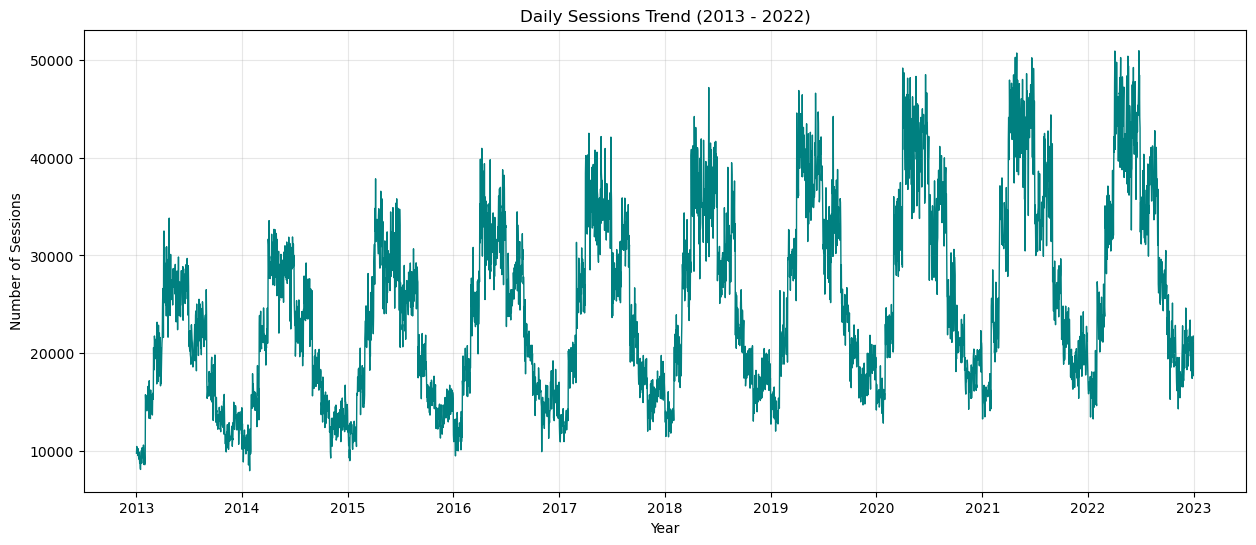

In [34]:
import matplotlib.dates as mdates

# 1. Biểu đồ xu hướng tổng thể (Daily Sessions)
plt.figure(figsize=(15, 6))
sns.lineplot(x='date', y='sessions', data=df_copy, color='teal', linewidth=1)
plt.title('Daily Sessions Trend (2013 - 2022)')
plt.xlabel('Year')
plt.ylabel('Number of Sessions')
plt.grid(True, alpha=0.3)
plt.show()

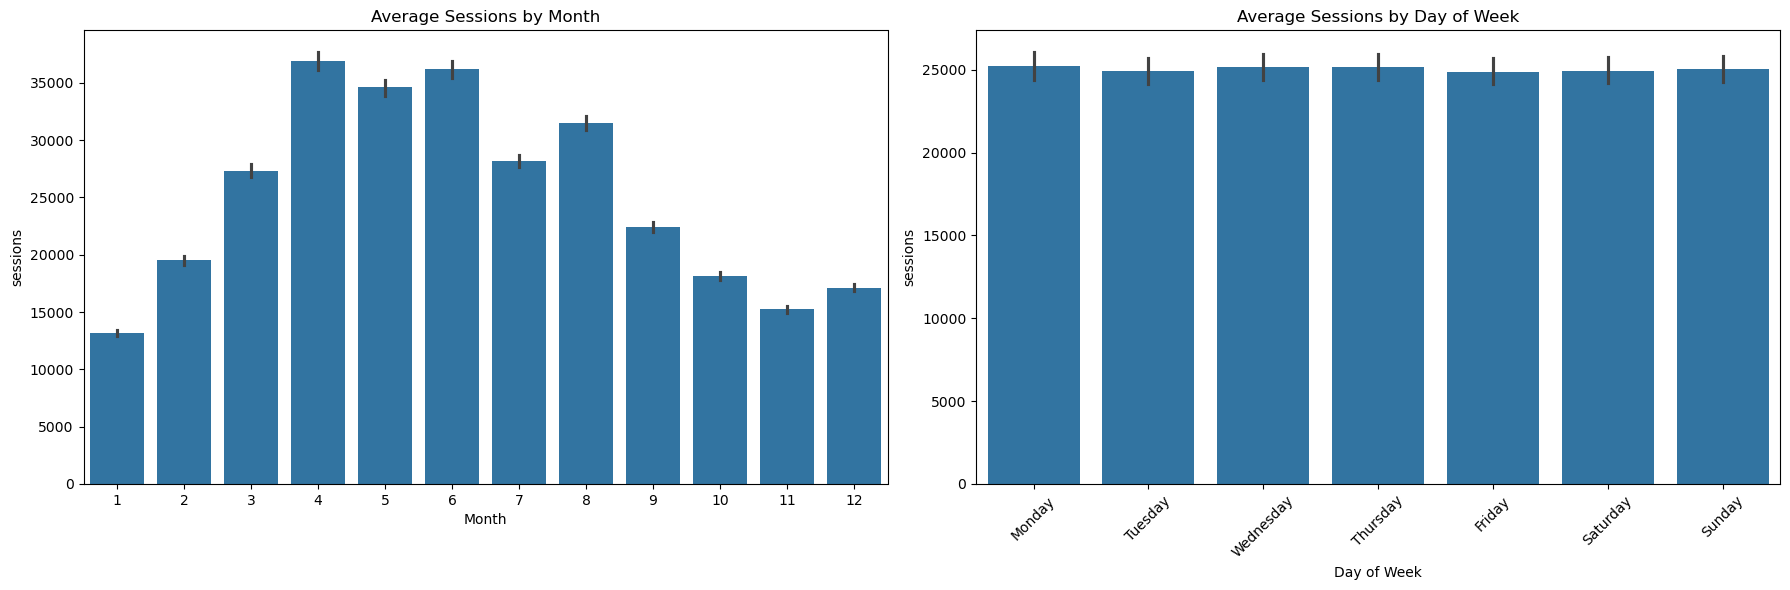

In [35]:
# Trích xuất thêm các thuộc tính thời gian
df_copy['month'] = df_copy['date'].dt.month
df_copy['day_of_week'] = df_copy['date'].dt.dayofweek
df_copy['day_name'] = df_copy['date'].dt.day_name()

# Sắp xếp thứ tự các ngày trong tuần
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# Phân tích theo tháng
sns.barplot(x='month', y='sessions', data=df_copy, ax=ax[0])
ax[0].set_title('Average Sessions by Month')
ax[0].set_xlabel('Month')

# Phân tích theo ngày trong tuần
sns.barplot(x='day_name', y='sessions', data=df_copy, ax=ax[1], order=day_order)
ax[1].set_title('Average Sessions by Day of Week')
ax[1].set_xlabel('Day of Week')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Nhận xét về Phân tích Chuỗi thời gian:**

**1. Xu hướng tổng thể (2013 - 2022):**
* Biểu đồ lưu lượng truy cập (`sessions`) cho thấy sự **tăng trưởng đều đặn và bền vững** trong suốt 10 năm qua.
* Lượng truy cập tăng từ mức trung bình khoảng 18.600 sessions/ngày (năm 2013) lên tới hơn 30.000 sessions/ngày (năm 2022).
* **Đánh giá:** Website đang phát triển rất tích cực, duy trì được đà tăng trưởng tốt và liên tục thu hút thêm người dùng mới theo thời gian.

**2. Tính mùa vụ theo Tháng (Monthly Seasonality):**
* Lưu lượng truy cập có sự **biến động rất mạnh** giữa các tháng trong năm.
* **Đỉnh điểm (Peak season):** Rơi vào Quý 2 và mùa hè (Tháng 4, 5, 6), ghi nhận mức truy cập cao nhất, có thể vượt qua 36.000 sessions/ngày.
* **Vùng thấp điểm (Off-season):** Rơi vào mùa Đông và dịp đầu năm/cuối năm (Tháng 1, 11, 12), lượng truy cập giảm sâu chỉ còn khoảng 13.000 - 15.000 sessions/ngày.
* **Đánh giá:** Website mang tính mùa vụ rất rõ rệt theo chu kỳ năm. Nội dung hoặc dịch vụ của website có thể liên quan đến các hoạt động diễn ra mạnh vào giữa năm (ví dụ: du lịch, tuyển sinh, kỳ nghỉ...).

**3. Tính mùa vụ theo Thứ trong tuần (Weekly Seasonality):**
* Trái ngược với sự biến động theo tháng, lưu lượng truy cập giữa các ngày trong tuần lại **cực kỳ đồng đều và ổn định**.
* Hoàn toàn không có sự chênh lệch giữa các ngày làm việc (Thứ 2 - Thứ 6) và ngày nghỉ (Thứ 7 - Chủ Nhật). Trung bình mỗi ngày đều đặn duy trì ở mức khoảng 25.000 sessions.
* **Đánh giá:** Nhu cầu truy cập của người dùng diễn ra mỗi ngày với tần suất không đổi, không bị phụ thuộc vào việc họ đang đi làm hay nghỉ ngơi cuối tuần.

**4. Tổng kết & Đề xuất chiến lược:**
* **Tổng kết:** Mô hình dữ liệu của website hội tụ đủ 3 yếu tố: Tăng trưởng tốt theo năm, có tính mùa vụ cao theo tháng (tập trung giữa năm) và cực kỳ ổn định theo ngày trong tuần.
* **Đề xuất chiến lược:** * Dồn trọng tâm ngân sách marketing và các chiến dịch tung sản phẩm/nội dung mới vào giai đoạn "mùa vàng" từ Tháng 4 đến Tháng 8 để tối đa hóa hiệu ứng.
  * Trong phạm vi một tuần, chiến lược phân phối nội dung và quảng cáo nên được **dàn trải đều cả 7 ngày** (không cần thiết phải phân bổ chênh lệch ngân sách giữa ngày thường và cuối tuần).
  * Về mặt kỹ thuật, cần tối ưu hóa hạ tầng máy chủ (server) vào Quý 2 để đảm bảo website không bị nghẽn mạng khi traffic tăng vọt đột biến.

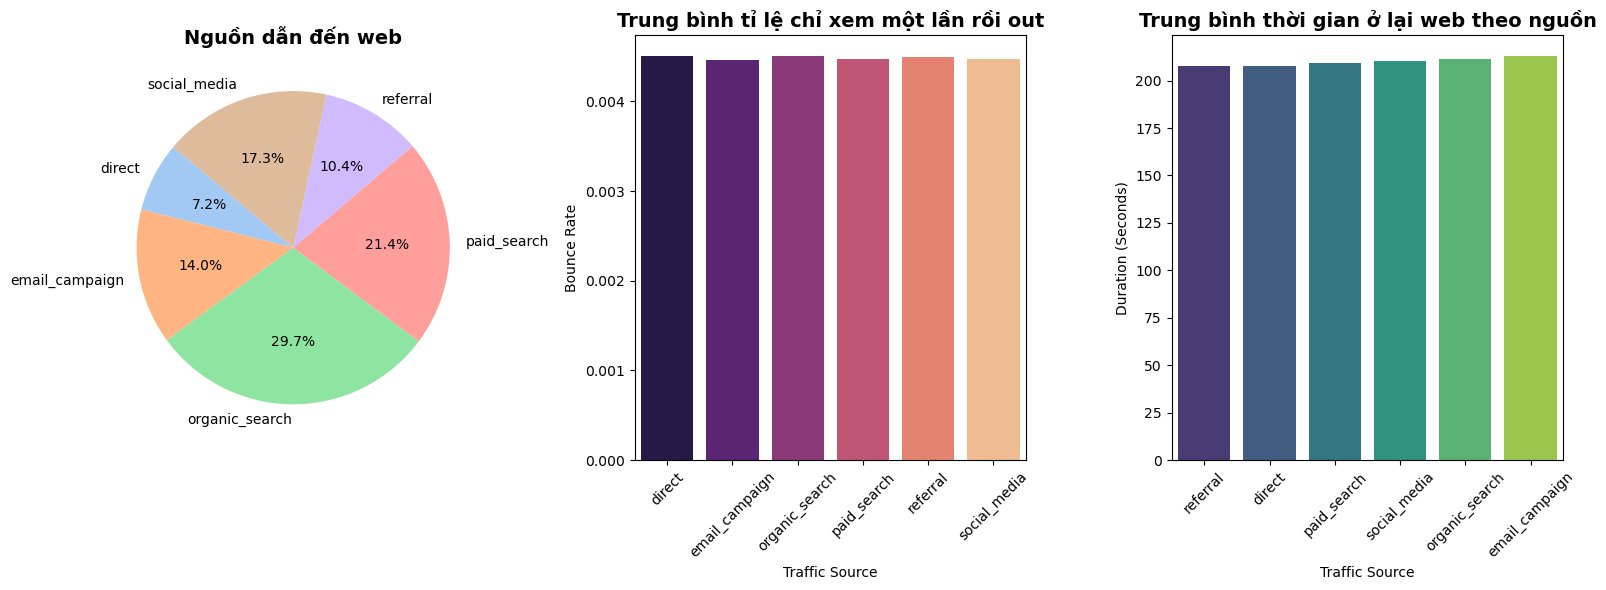

,traffic_source,total_sessions,avg_bounce_rate,avg_duration,session_percentage
2,organic_search,27196976,0.004504,211.153945,29.738897
3,paid_search,19598271,0.004478,209.362117,21.429992
5,social_media,15816226,0.004476,210.290190,17.294464
1,email_campaign,12792670,0.004458,213.220594,13.988316
4,referral,9476845,0.004499,207.558667,10.362583
0,direct,6571549,0.004511,207.678195,7.185748


In [37]:
# 1. Thống kê số lượng sessions theo nguồn
traffic_summary = df_copy.groupby('traffic_source').agg(
    total_sessions=('sessions', 'sum'),
    avg_bounce_rate=('bounce_rate', 'mean'),
    avg_duration=('avg_session_duration_sec', 'mean')
).reset_index()

# Tính tỷ lệ % đóng góp
traffic_summary['session_percentage'] = (traffic_summary['total_sessions'] / traffic_summary['total_sessions'].sum()) * 100

# 2. Trực quan hóa (Gộp 3 biểu đồ vào 1 Figure)
fig, ax = plt.subplots(1, 3, figsize=(16, 6)) # Tạo layout 1 hàng, 3 cột

# Biểu đồ 1 (Cột trái): Tỷ lệ sessions
ax[0].pie(traffic_summary['total_sessions'], labels=traffic_summary['traffic_source'], autopct='%1.1f%%',
          startangle=140, colors=sns.color_palette('pastel'))
ax[0].set_title('Nguồn dẫn đến web', fontsize=14, fontweight='bold')

# Biểu đồ 2 (Cột giữa): So sánh Bounce Rate giữa các nguồn
sns.barplot(x='traffic_source', y='avg_bounce_rate', data=traffic_summary, ax=ax[1], palette='magma')
ax[1].set_title('Trung bình tỉ lệ chỉ xem một lần rồi out', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Bounce Rate')
ax[1].set_xlabel('Traffic Source')
ax[1].tick_params(axis='x', rotation=45) # Xoay nhãn trục X 45 độ cho dễ đọc

# Biểu đồ 3 (Cột phải): So sánh thời lượng phiên trung bình
sns.barplot(x='traffic_source', y='avg_duration', data=traffic_summary.sort_values('avg_duration'), ax=ax[2], palette='viridis')
ax[2].set_title('Trung bình thời gian ở lại web theo nguồn', fontsize=14, fontweight='bold')
ax[2].set_xlabel('Traffic Source')
ax[2].set_ylabel('Duration (Seconds)')
ax[2].tick_params(axis='x', rotation=45) # Xoay nhãn trục X 45 độ

plt.tight_layout()
plt.show()

# 3. Hiển thị bảng dữ liệu (để xem chi tiết con số)
display(traffic_summary.sort_values(by='total_sessions', ascending=False))

**Nhận xét về Nguồn Truy cập (Traffic Sources):**

**1. Tỷ trọng các nguồn truy cập (Traffic Share):**
* **Tìm kiếm tự nhiên (Organic Search)** là kênh mang lại nhiều traffic nhất, đóng góp gần **30%** tổng lượng truy cập. Điều này cho thấy website có chiến lược SEO (Tối ưu hóa công cụ tìm kiếm) rất tốt và đang tiếp cận đúng tệp người dùng.
* Đứng thứ hai là **Paid Search** (Quảng cáo trả phí) chiếm **21.4%**. Có thể thấy website kết hợp rất nhịp nhàng giữa cả traffic tự nhiên và traffic dùng ngân sách quảng cáo.
* Kênh **Direct** (Truy cập trực tiếp) chiếm tỷ trọng thấp nhất (chỉ **7.2%**). Điều này cho thấy người dùng hiếm khi chủ động gõ trực tiếp tên miền vào trình duyệt để vào web.

**2. Tỷ lệ thoát (Average Bounce Rate):**
* Điểm đặc biệt là tỷ lệ thoát giữa tất cả các nguồn truy cập **cực kỳ đồng đều** (dao động rất hẹp quanh mức 0.0044 - 0.0045).
* **Đánh giá:** Trải nghiệm trang đích (Landing Page) được tối ưu hóa đồng bộ rất tốt. Dù người dùng đến từ bài post Facebook (Social Media), click từ quảng cáo (Paid Search) hay từ Email, họ đều có trải nghiệm nhất quán và tỷ lệ thoát trang gần như tương đương nhau.

**3. Thời lượng phiên trung bình (Average Session Duration):**
* Giống như Bounce Rate, thời gian người dùng ở lại trang giữa các kênh rất đồng đều, trung bình dao động từ **207 đến 213 giây** (khoảng 3.5 phút/phiên). Đây là một thời lượng khá ấn tượng.

**4. Tổng kết & Đề xuất chiến lược:**
* **Bảo vệ "mỏ vàng" SEO:** Tiếp tục đầu tư nội dung chất lượng cao để duy trì vị thế của Organic Search. Đây là nguồn traffic bền vững và mang lại sự gắn kết tốt.
* **Tối ưu hóa phễu Email:** Vì Email mang lại thời gian tương tác cao nhất (thời gian on-site lâu), hãy thiết kế thêm các pop-up hoặc form thu thập email người dùng trên web để mở rộng tệp khách hàng tiềm năng này.
* **Xây dựng nhận diện thương hiệu:** Tỷ lệ Direct traffic khá thấp chứng tỏ "Brand Awareness" chưa cao. Đội ngũ Marketing cần tạo ra những chiến dịch hoặc nội dung mang tính "độc quyền" để kích thích người dùng nhớ tên thương hiệu và chủ động gõ URL truy cập trực tiếp trong tương lai.

In [39]:
df_copy.to_csv(pathDataCleaned + "web_traffic_cleaned.csv", index=False)